## Nama    : Dirga Alin Cristin Rero
## NIM     : H061241016

# <center>TUGAS AI</center>


### 1. SEISMIK REFRAKSI

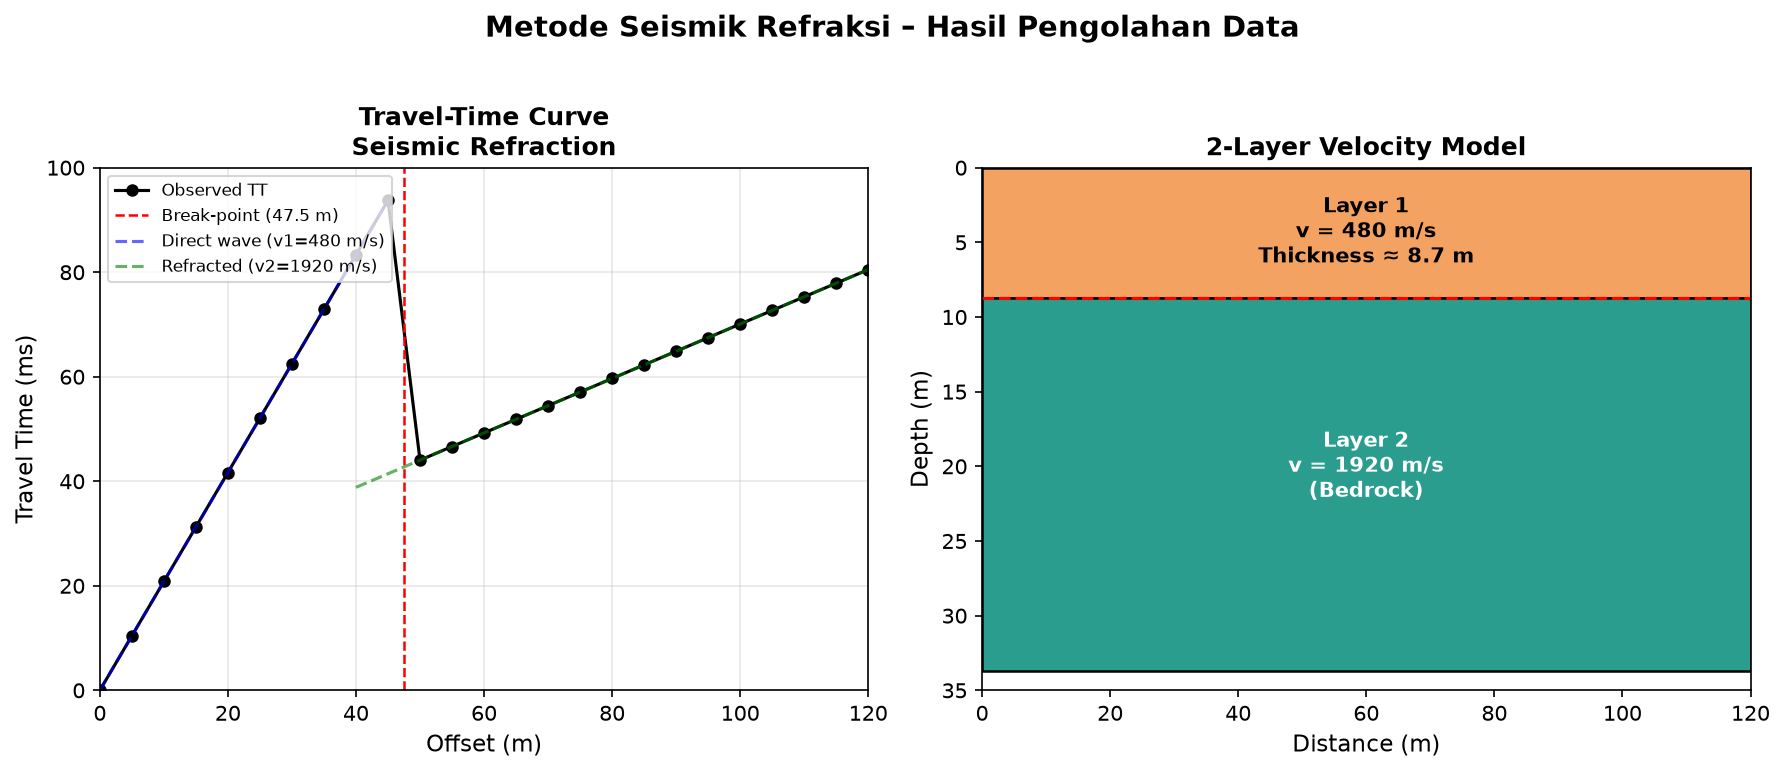

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Travel-time curve ---
offset = np.linspace(0, 120, 25)
t_direct = offset / 0.48          # v1 = 480 m/s
t_refracted = 18 + offset / 1.92  # v2 = 1920 m/s
tt = np.where(offset < 47.5, t_direct, t_refracted)

axes[0].plot(offset, tt, 'ko-', markersize=5, linewidth=1.5, label='Observed TT')
axes[0].axvline(47.5, color='red', linestyle='--', linewidth=1.2, label='Break-point (47.5 m)')
axes[0].plot(offset[offset < 47.5], t_direct[offset < 47.5], 'b--', alpha=0.6, label='Direct wave (v1=480 m/s)')
axes[0].plot(offset[offset >= 40], t_refracted[offset >= 40], 'g--', alpha=0.6, label='Refracted (v2=1920 m/s)')
axes[0].set_xlabel('Offset (m)', fontsize=11)
axes[0].set_ylabel('Travel Time (ms)', fontsize=11)
axes[0].set_title('Travel-Time Curve\nSeismic Refraction', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=8, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, 120)
axes[0].set_ylim(0, 100)

# --- Model kecepatan 2 lapis ---
ax = axes[1]
ax.add_patch(Rectangle((0, 0), 120, 8.7, facecolor='#f4a261', edgecolor='black', linewidth=1.2))
ax.text(60, 4.3, 'Layer 1\nv = 480 m/s\nThickness ≈ 8.7 m', ha='center', va='center', fontsize=10, fontweight='bold')
ax.add_patch(Rectangle((0, 8.7), 120, 25, facecolor='#2a9d8f', edgecolor='black', linewidth=1.2))
ax.text(60, 20, 'Layer 2\nv = 1920 m/s\n(Bedrock)', ha='center', va='center', fontsize=10, fontweight='bold', color='white')
ax.set_xlim(0, 120)
ax.set_ylim(35, 0)
ax.set_xlabel('Distance (m)', fontsize=11)
ax.set_ylabel('Depth (m)', fontsize=11)
ax.set_title('2-Layer Velocity Model', fontsize=12, fontweight='bold')
ax.axhline(8.7, color='red', linestyle='--', linewidth=1.5)

plt.suptitle('Metode Seismik Refraksi – Hasil Pengolahan Data', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('01_seismik_refraksi.png')
plt.show()

### 2. INDUCED POLARIZATION

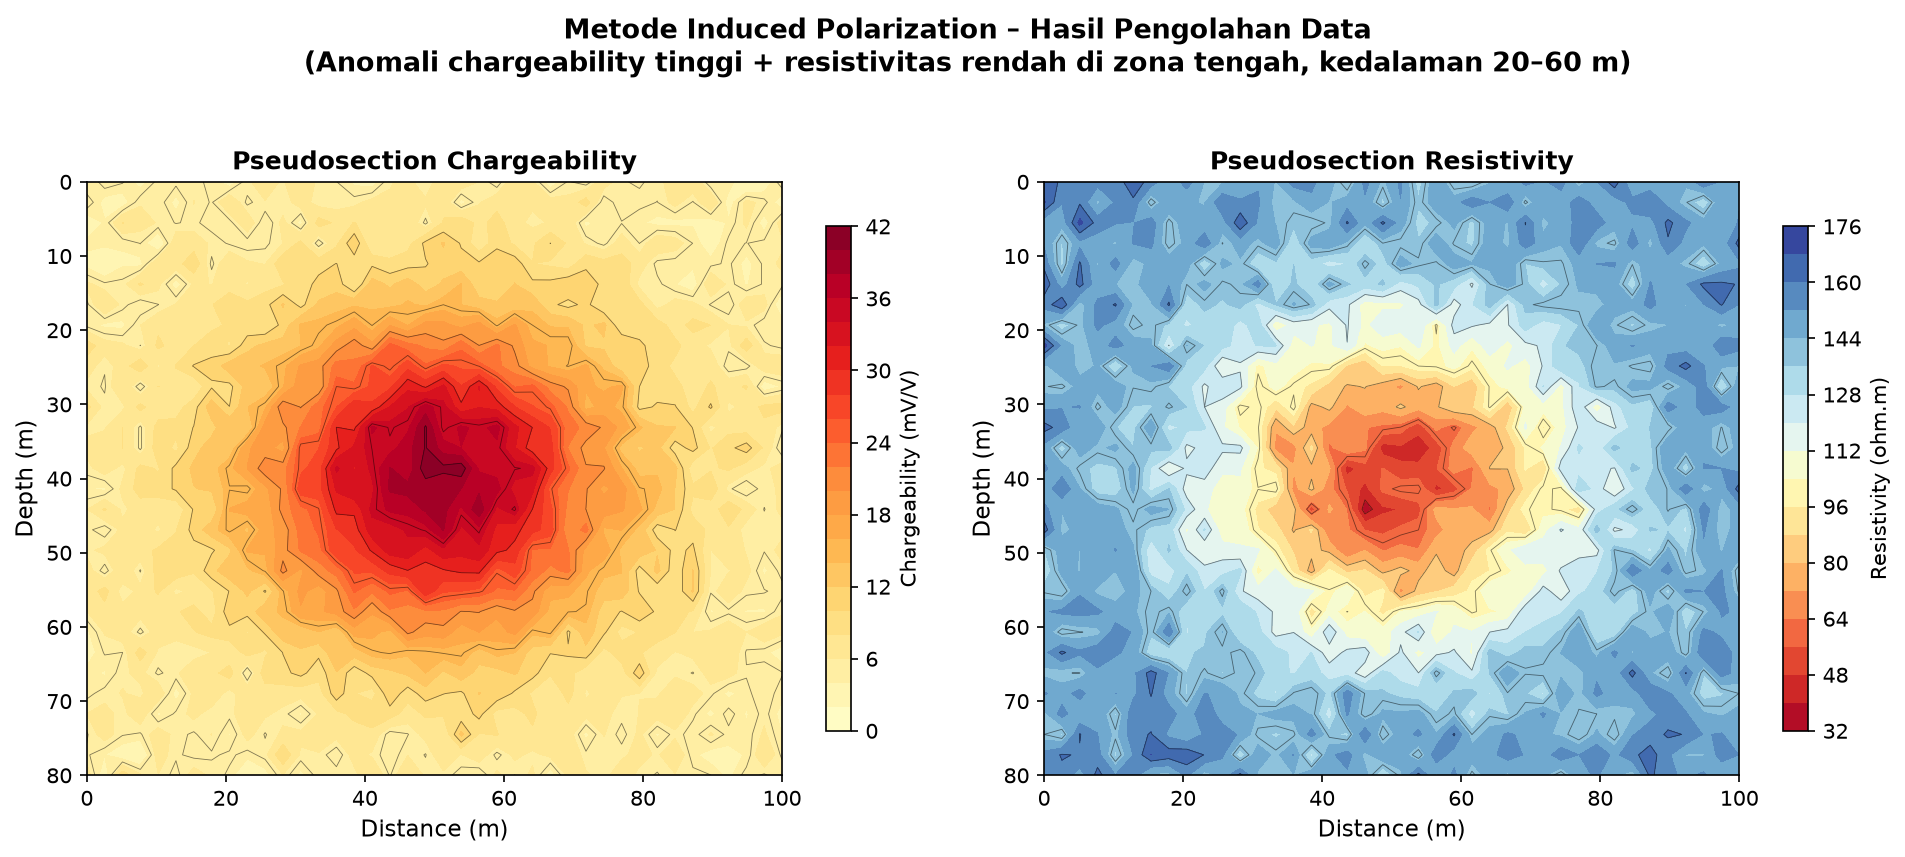

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

x = np.linspace(0, 100, 40)
z = np.linspace(0, 80, 30)
X, Z = np.meshgrid(x, z)

# Anomali chargeability tinggi di tengah (kedalaman 20-60 m)
charge = 5 + 35 * np.exp(-((X-50)**2)/(2*18**2) - ((Z-40)**2)/(2*15**2))
charge += np.random.normal(0, 1.5, charge.shape)

# Resistivitas rendah di zona yang sama
resist = 150 - 100 * np.exp(-((X-50)**2)/(2*18**2) - ((Z-40)**2)/(2*15**2))
resist += np.random.normal(0, 8, resist.shape)
resist = np.clip(resist, 20, 200)

# Pseudosection Chargeability
im0 = axes[0].contourf(X, Z, charge, levels=20, cmap='YlOrRd')
axes[0].contour(X, Z, charge, levels=8, colors='k', linewidths=0.4, alpha=0.5)
cbar0 = plt.colorbar(im0, ax=axes[0], shrink=0.85)
cbar0.set_label('Chargeability (mV/V)', fontsize=10)
axes[0].set_xlabel('Distance (m)', fontsize=11)
axes[0].set_ylabel('Depth (m)', fontsize=11)
axes[0].set_title('Pseudosection Chargeability', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()
axes[0].set_xlim(0, 100)
axes[0].set_ylim(80, 0)

# Pseudosection Resistivity
im1 = axes[1].contourf(X, Z, resist, levels=20, cmap='RdYlBu')
axes[1].contour(X, Z, resist, levels=8, colors='k', linewidths=0.4, alpha=0.5)
cbar1 = plt.colorbar(im1, ax=axes[1], shrink=0.85)
cbar1.set_label('Resistivity (ohm.m)', fontsize=10)
axes[1].set_xlabel('Distance (m)', fontsize=11)
axes[1].set_ylabel('Depth (m)', fontsize=11)
axes[1].set_title('Pseudosection Resistivity', fontsize=12, fontweight='bold')
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_ylim(80, 0)

plt.suptitle('Metode Induced Polarization – Hasil Pengolahan Data\n(Anomali chargeability tinggi + resistivitas rendah di zona tengah, kedalaman 20–60 m)', 
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('02_induced_polarization.png')
plt.show()

### 3. MAGNETOTELURIK

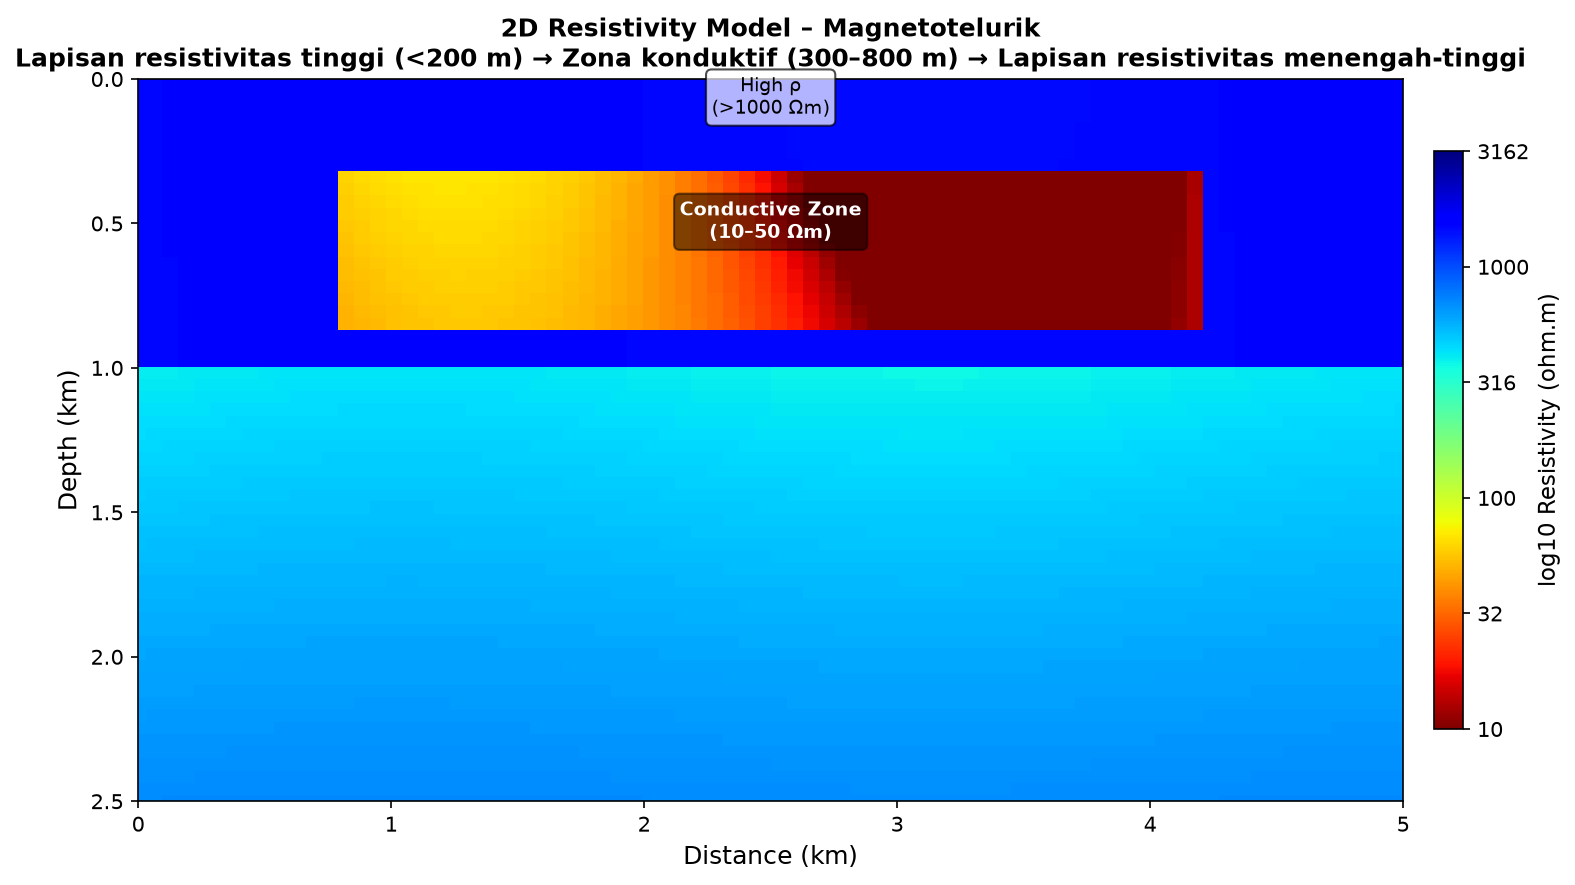

In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

fig, ax = plt.subplots(figsize=(11, 6))

x_mt = np.linspace(0, 5, 80)      # km
z_mt = np.linspace(0, 2.5, 60)    # km
Xmt, Zmt = np.meshgrid(x_mt, z_mt)

# Model resistivitas
res_mt = np.ones_like(Xmt) * 1500.0
mask_cond = (Zmt > 0.3) & (Zmt < 0.85) & (Xmt > 0.8) & (Xmt < 4.2)
res_mt[mask_cond] = 25 + 15 * np.sin((Xmt[mask_cond]-0.8)*1.2)
mask_deep = Zmt > 1.0
res_mt[mask_deep] = 400 + 200 * (Zmt[mask_deep]-1.0)
res_mt += 50 * np.sin(Xmt * 1.5) * np.exp(-Zmt*0.8)
res_mt = np.clip(res_mt, 8, 5000)

im = ax.pcolormesh(Xmt, Zmt, np.log10(res_mt), cmap='jet_r', shading='auto', vmin=1.0, vmax=3.5)
cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label('log10 Resistivity (ohm.m)', fontsize=11)
cbar.set_ticks([1.0, 1.5, 2.0, 2.5, 3.0, 3.5])
cbar.set_ticklabels(['10', '32', '100', '316', '1000', '3162'])

ax.set_xlabel('Distance (km)', fontsize=12)
ax.set_ylabel('Depth (km)', fontsize=12)
ax.set_title('2D Resistivity Model – Magnetotelurik\nLapisan resistivitas tinggi (<200 m) → Zona konduktif (300–800 m) → Lapisan resistivitas menengah-tinggi', 
             fontsize=12, fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, 5)
ax.set_ylim(2.5, 0)

ax.annotate('High ρ\n(>1000 Ωm)', xy=(2.5, 0.12), fontsize=9, ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.annotate('Conductive Zone\n(10–50 Ωm)', xy=(2.5, 0.55), fontsize=9, ha='center', color='white',
            fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))

plt.tight_layout()
plt.savefig('03_magnetotelurik.png')
plt.show()

### 4. HVSR 

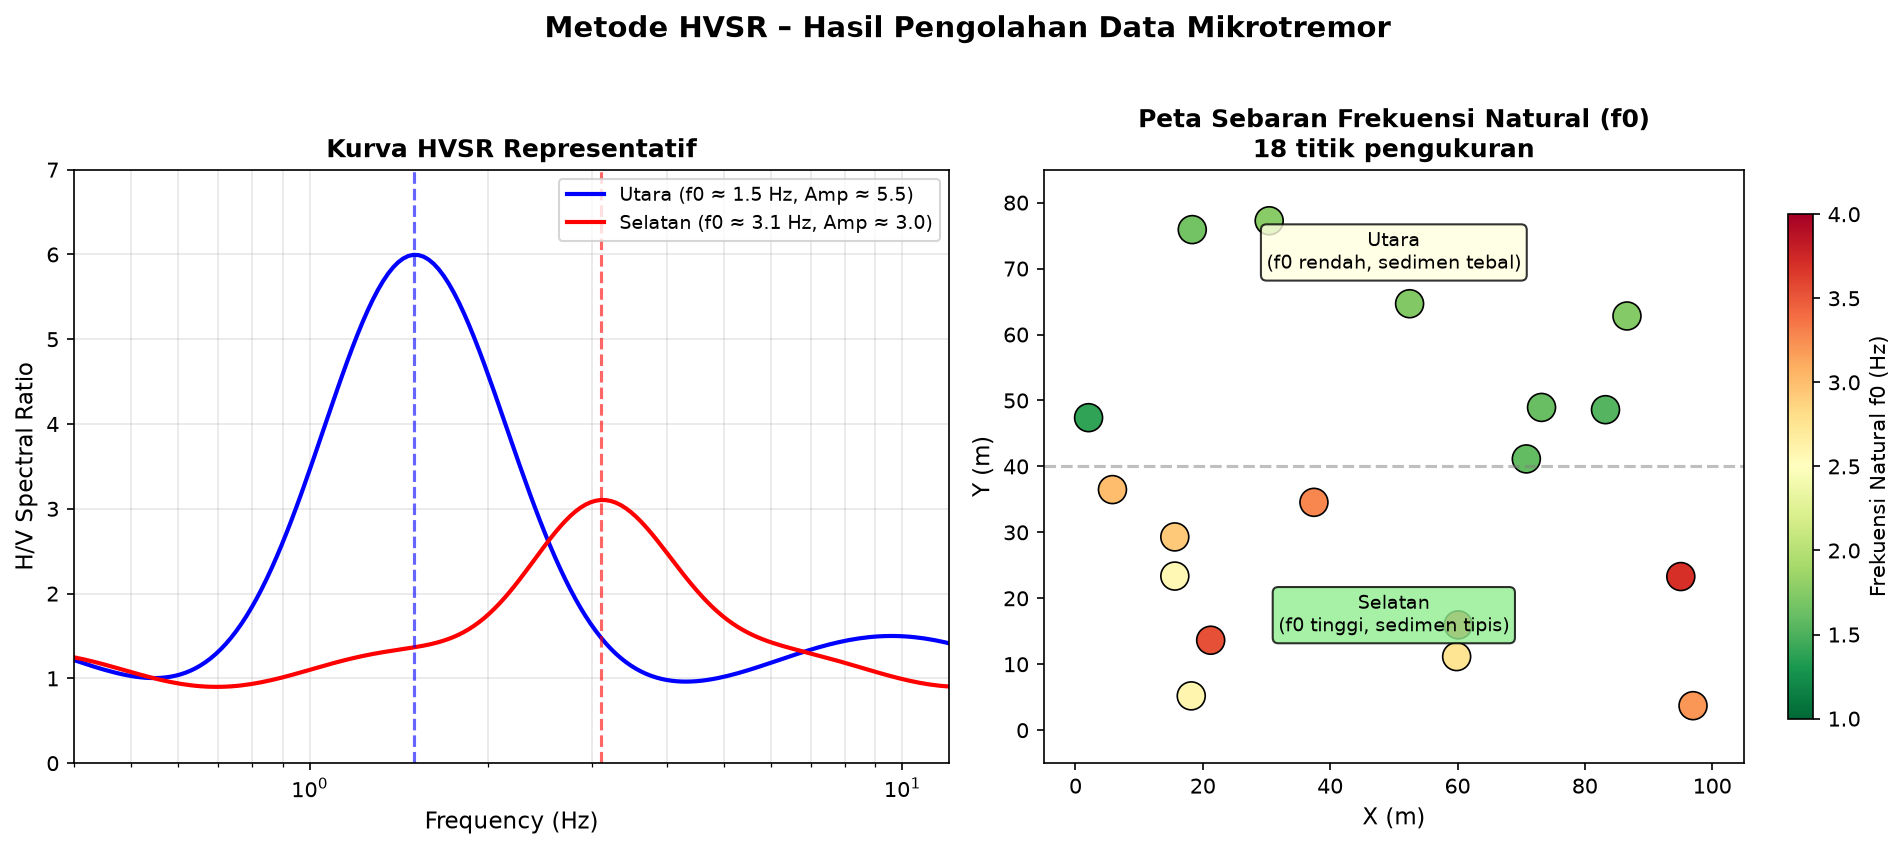

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

fig = plt.figure(figsize=(13, 5.5))

# --- Kurva HVSR ---
ax1 = fig.add_subplot(121)
freq = np.logspace(-0.5, 1.2, 200)

hvsr_n = 1.2 + 4.5 * np.exp(-((np.log10(freq)-np.log10(1.5))**2)/(2*0.15**2))
hvsr_n += 0.3 * np.sin(np.log10(freq)*8)

hvsr_s = 1.1 + 2.2 * np.exp(-((np.log10(freq)-np.log10(3.1))**2)/(2*0.12**2))
hvsr_s += 0.2 * np.sin(np.log10(freq)*10)

ax1.semilogx(freq, hvsr_n, 'b-', linewidth=2, label='Utara (f0 ≈ 1.5 Hz, Amp ≈ 5.5)')
ax1.semilogx(freq, hvsr_s, 'r-', linewidth=2, label='Selatan (f0 ≈ 3.1 Hz, Amp ≈ 3.0)')
ax1.axvline(1.5, color='b', linestyle='--', alpha=0.6)
ax1.axvline(3.1, color='r', linestyle='--', alpha=0.6)
ax1.set_xlabel('Frequency (Hz)', fontsize=11)
ax1.set_ylabel('H/V Spectral Ratio', fontsize=11)
ax1.set_title('Kurva HVSR Representatif', fontsize=12, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, which='both', alpha=0.3)
ax1.set_xlim(0.4, 12)
ax1.set_ylim(0, 7)

# --- Peta sebaran f0 ---
ax2 = fig.add_subplot(122)
np.random.seed(42)
n_pts = 18
x_h = np.random.uniform(0, 100, n_pts)
y_h = np.random.uniform(0, 80, n_pts)
f0 = np.where(y_h > 40, 
              np.random.uniform(1.2, 1.8, n_pts), 
              np.random.uniform(2.5, 3.8, n_pts))

sc = ax2.scatter(x_h, y_h, c=f0, s=180, cmap='RdYlGn_r', edgecolors='k', linewidths=0.8, vmin=1.0, vmax=4.0)
cbar2 = plt.colorbar(sc, ax=ax2, shrink=0.85)
cbar2.set_label('Frekuensi Natural f0 (Hz)', fontsize=10)
ax2.set_xlabel('X (m)', fontsize=11)
ax2.set_ylabel('Y (m)', fontsize=11)
ax2.set_title('Peta Sebaran Frekuensi Natural (f0)\n18 titik pengukuran', fontsize=12, fontweight='bold')
ax2.set_xlim(-5, 105)
ax2.set_ylim(-5, 85)
ax2.axhline(40, color='gray', linestyle='--', alpha=0.5)
ax2.text(50, 70, 'Utara\n(f0 rendah, sedimen tebal)', ha='center', fontsize=9, 
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
ax2.text(50, 15, 'Selatan\n(f0 tinggi, sedimen tipis)', ha='center', fontsize=9,
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))

plt.suptitle('Metode HVSR – Hasil Pengolahan Data Mikrotremor', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('04_hvsr.png')
plt.show()

### 5. GEOMAGNET

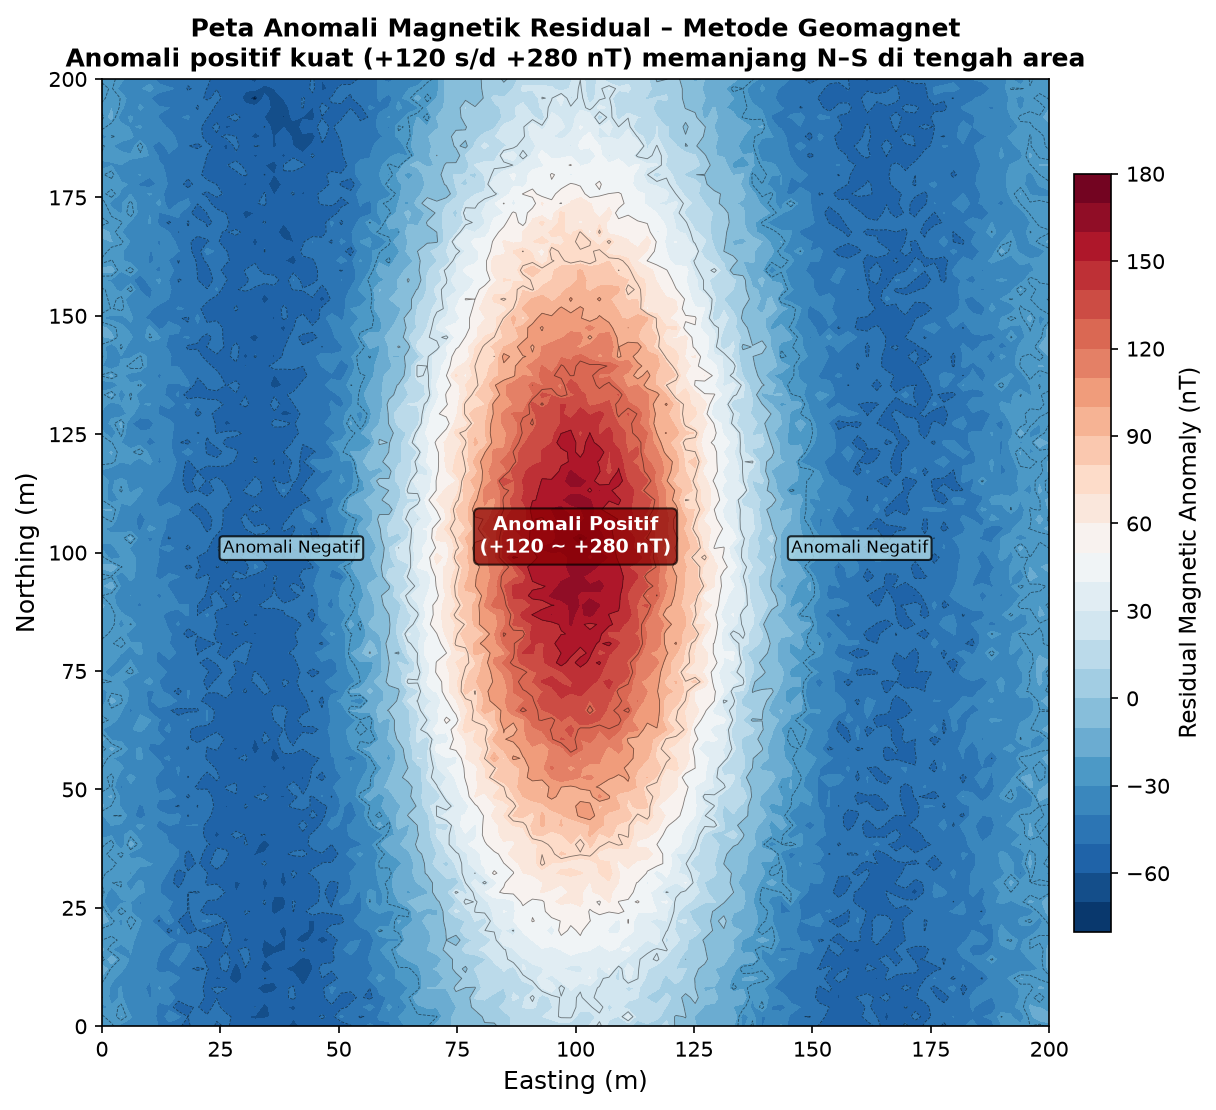

In [7]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

fig, ax = plt.subplots(figsize=(9, 7.5))

xg = np.linspace(0, 200, 100)
yg = np.linspace(0, 200, 100)
Xg, Yg = np.meshgrid(xg, yg)

# Anomali positif kuat memanjang utara-selatan di tengah
anom = 180 * np.exp(-((Xg-100)**2)/(2*25**2)) * np.exp(-((Yg-100)**2)/(2*55**2))
anom -= 60 * np.exp(-((Xg-40)**2)/(2*30**2))   # anomali negatif barat
anom -= 55 * np.exp(-((Xg-160)**2)/(2*30**2))  # anomali negatif timur
anom += np.random.normal(0, 5, anom.shape)

im = ax.contourf(Xg, Yg, anom, levels=25, cmap='RdBu_r')
ax.contour(Xg, Yg, anom, levels=10, colors='k', linewidths=0.4, alpha=0.5)
cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label('Residual Magnetic Anomaly (nT)', fontsize=11)

ax.set_xlabel('Easting (m)', fontsize=12)
ax.set_ylabel('Northing (m)', fontsize=12)
ax.set_title('Peta Anomali Magnetik Residual – Metode Geomagnet\nAnomali positif kuat (+120 s/d +280 nT) memanjang N–S di tengah area', 
             fontsize=12, fontweight='bold')
ax.set_aspect('equal')

ax.annotate('Anomali Positif\n(+120 ~ +280 nT)', xy=(100, 100), fontsize=9, ha='center',
            color='white', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='darkred', alpha=0.7))
ax.annotate('Anomali Negatif', xy=(40, 100), fontsize=8, ha='center',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='lightblue', alpha=0.8))
ax.annotate('Anomali Negatif', xy=(160, 100), fontsize=8, ha='center',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='lightblue', alpha=0.8))

plt.tight_layout()
plt.savefig('05_geomagnet.png')
plt.show()